# Operación Olist: Caos, Clientes y Algoritmos Desatados

En este proyecto se resuelven 3 de las 5 misiones que planteaba el desafío, las misiones corresponden al dataset público de Olist. Están ordenadas de la 1 a la 5 por orden de misión dependiendo de las que se fueron realizando.

- **Misión 1: ¿qué clientes vuelven a comprar?** Se comparan 6 modelos (Decision Tree, Random Forest, Gradient Boosting, SVM lineal, kNN y Naive Bayes) para predecir qué clientes vuelven y cuáles no.
- **Misión 3: ¿cuántos días tarda una entrega?** Se comparan 3 modelos de regresión (Decision Tree, Random Forest y Gradient Boosting) para predecir cuántos días tarda en llegar un pedido.
- **Misión 5: ¿qué reseñas son negativas?** Se comparan la SVM lineal y Naive Bayes para predecir si el texto de una reseña es negativo o positivo.

La exploración de los datos está al principio del notebook y, luego, cada misión tiene su propio preprocesamiento, un modelo de base, el entrenamiento y la comparación de modelos con `cross_validate`, un gráfico, la evaluación final con el conjunto de prueba y las conclusiones.

## Exploración de datos
### Tabla de pedidos

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, recall_score
from sklearn.model_selection import cross_validate
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import confusion_matrix, precision_score, f1_score, mean_absolute_error, root_mean_squared_error, r2_score
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, RandomForestRegressor, GradientBoostingRegressor
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.dummy import DummyRegressor
from sklearn.feature_extraction.text import TfidfVectorizer

orders = pd.read_csv("archive/olist_orders_dataset.csv")
print(orders.shape)
print(orders.info())
orders.head()

(99441, 8)
<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   order_id                       99441 non-null  str  
 1   customer_id                    99441 non-null  str  
 2   order_status                   99441 non-null  str  
 3   order_purchase_timestamp       99441 non-null  str  
 4   order_approved_at              99281 non-null  str  
 5   order_delivered_carrier_date   97658 non-null  str  
 6   order_delivered_customer_date  96476 non-null  str  
 7   order_estimated_delivery_date  99441 non-null  str  
dtypes: str(8)
memory usage: 6.1 MB
None


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


La tabla de pedidos tiene 99.441 filas y 8 columnas. Las columnas de fechas están guardadas como texto, así que habrá que convertirlas antes de poder restarlas. Además, faltan valores en tres de ellas: 160 en `order_approved_at`, 1.783 en `order_delivered_carrier_date` y 2.965 en `order_delivered_customer_date`.

In [2]:
import warnings
from sklearn.exceptions import UndefinedMetricWarning

# Se silencian las advertencias esperadas de Precision cuando un modelo no predice ninguna clase positiva
warnings.filterwarnings("ignore", category=UndefinedMetricWarning)

In [3]:
print(orders["order_status"].value_counts())
print(orders.isna().sum())

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64


El estado más común es `delivered` (96.478 pedidos); el resto se reparte entre `shipped`, `canceled`, `unavailable`, `invoiced`, `processing`, `created` y `approved`.

In [4]:
sin_fecha = orders[orders["order_delivered_customer_date"].isna()]
print(sin_fecha["order_status"].value_counts())

entregados_sin_fecha = orders[(orders["order_status"] == "delivered") & (orders["order_delivered_customer_date"].isna())]
print(entregados_sin_fecha.shape)

order_status
shipped        1107
canceled        619
unavailable     609
invoiced        314
processing      301
delivered         8
created           5
approved          2
Name: count, dtype: int64
(8, 8)


De los 2.965 pedidos sin fecha de entrega, la mayoría no figura como entregada (`shipped`: 1.107, `canceled`: 619, `unavailable`: 609, entre otros). Sin embargo, 8 pedidos figuran como `delivered` y no tienen fecha de entrega. No se puede saber la causa con estos datos; podría ser un error de carga o un cambio de estado posterior.

In [5]:
orders["order_purchase_timestamp"] = pd.to_datetime(orders["order_purchase_timestamp"])
orders["order_delivered_customer_date"] = pd.to_datetime(orders["order_delivered_customer_date"])

orders["dias_entrega"] = (orders["order_delivered_customer_date"] - orders["order_purchase_timestamp"]).dt.days
print(orders["dias_entrega"].describe())

count    96476.000000
mean        12.094086
std          9.551746
min          0.000000
25%          6.000000
50%         10.000000
75%         15.000000
max        209.000000
Name: dias_entrega, dtype: float64


Se calculó el tiempo de entrega como los días entre la fecha de compra y la fecha de entrega al cliente, para los 96.476 pedidos que tienen ambos datos. En promedio una entrega tarda 12,1 días y la mitad tarda 10 días o menos; el 75% llega en 15 días o menos. El mínimo es 0 días (menos de 24 horas) y el máximo es 209, muy lejos del resto de los valores.

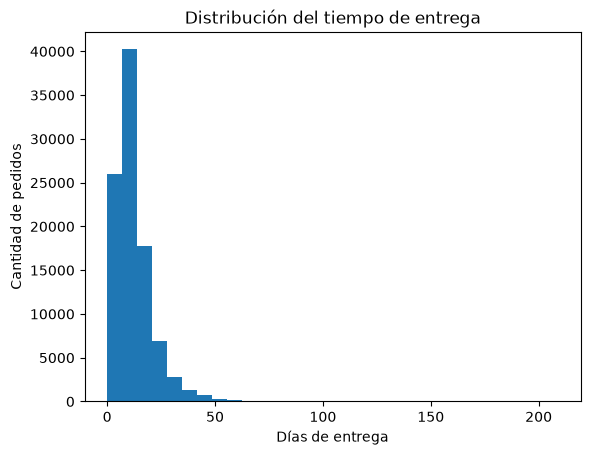

In [6]:
plt.hist(orders["dias_entrega"].dropna(), bins=30)
plt.xlabel("Días de entrega")
plt.ylabel("Cantidad de pedidos")
plt.title("Distribución del tiempo de entrega")
plt.show()

In [7]:
print((orders["dias_entrega"] > 60).sum())
print((orders["dias_entrega"] > 100).sum())
print((orders["dias_entrega"] > 150).sum())

288
63
24


In [8]:
print((orders["dias_entrega"] > 60).sum() / orders["dias_entrega"].notna().sum())

0.002985198391309756


En los datos y en el gráfico se puede apreciar que la mitad de los pedidos tarda 10 días o menos y el 75% llega para los 15 días, los demás llegan a los 60 días o menos. Sin embargo, hay una minoría, 0,3%, que llega luego de los 60 días, son un total de 288 de los 96.476 pedidos con fecha de entrega. De estos 288, 63 superaron los 100 días y 24 los 150. Los datos no revelan por qué estos pedidos llegan tan tarde, una hipótesis es que se trata de pedidos en zonas lejanas del país o pedidos que se extravían y se vuelven a recuperar.

### Tabla de clientes

In [9]:
customers = pd.read_csv("archive/olist_customers_dataset.csv")
print(customers.shape)
print(customers.head())
customers.info()

(99441, 5)
                        customer_id                customer_unique_id  \
0  06b8999e2fba1a1fbc88172c00ba8bc7  861eff4711a542e4b93843c6dd7febb0   
1  18955e83d337fd6b2def6b18a428ac77  290c77bc529b7ac935b93aa66c333dc3   
2  4e7b3e00288586ebd08712fdd0374a03  060e732b5b29e8181a18229c7b0b2b5e   
3  b2b6027bc5c5109e529d4dc6358b12c3  259dac757896d24d7702b9acbbff3f3c   
4  4f2d8ab171c80ec8364f7c12e35b23ad  345ecd01c38d18a9036ed96c73b8d066   

   customer_zip_code_prefix          customer_city customer_state  
0                     14409                 franca             SP  
1                      9790  sao bernardo do campo             SP  
2                      1151              sao paulo             SP  
3                      8775        mogi das cruzes             SP  
4                     13056               campinas             SP  
<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 5 columns):
 #   Column                    Non-Null Count

In [10]:
print(customers["customer_id"].nunique())
print(customers["customer_unique_id"].nunique())

99441
96096


La tabla de clientes tiene 99.441 filas y 5 columnas, sin valores nulos. Tiene dos identificadores: `customer_id`, con 99.441 valores distintos (uno por fila), y `customer_unique_id`, con 96.096. Esa diferencia indica que algunos clientes aparecen en más de una fila.

In [11]:
filas_por_persona = customers["customer_unique_id"].value_counts()
print(filas_por_persona.value_counts())

count
1     93099
2      2745
3       203
4        30
5         8
6         6
7         3
17        1
9         1
Name: count, dtype: int64


De esos 96.096 clientes, 93.099 aparecen en una sola fila y el resto en 2 o más, hasta un máximo de 17.

### Unión de pedidos y clientes

In [12]:
pedidos_clientes = pd.merge(orders, customers, on="customer_id", how="left")
print(pedidos_clientes.shape)
print(pedidos_clientes["customer_unique_id"].isna().sum())
print(pedidos_clientes["customer_unique_id"].value_counts().value_counts())

(99441, 13)
0
count
1     93099
2      2745
3       203
4        30
5         8
6         6
7         3
17        1
9         1
Name: count, dtype: int64


Al unir la tabla de pedidos con la de clientes por `customer_id`, el resultado mantiene las 99.441 filas y no hay ningún nulo en `customer_unique_id`, es decir, todos los pedidos encontraron a su cliente. La distribución de pedidos por persona es la misma que la de filas por persona, en la tabla de clientes 93.099 personas tienen un solo pedido y el máximo es 17.

In [13]:
entregados = pedidos_clientes[pedidos_clientes["order_status"] == "delivered"]
print(entregados["customer_unique_id"].nunique())
print(entregados["customer_unique_id"].value_counts().value_counts())

93358
count
1     90557
2      2573
3       181
4        28
5         9
6         5
7         3
15        1
9         1
Name: count, dtype: int64


In [14]:
total = entregados["customer_unique_id"].nunique()
una_compra = (entregados["customer_unique_id"].value_counts() == 1).sum()
print(una_compra / total)
print(1 - una_compra / total)

0.9699972150217443
0.030002784978255703


### Definición de la variable a predecir

Se define que un cliente "volvió" si realizó más de una compra entregada, sin importar cuánto tiempo pasó entre ellas. Se eligió esta definición, en lugar de la de 30 días del enunciado, porque un cliente puede volver a comprar a los dos o tres meses y no por eso se fue. Entre las personas con pedidos entregados, el 97% compró una sola vez y el 3% más de una.

In [15]:
compras_por_persona = entregados["customer_unique_id"].value_counts()
volvio = compras_por_persona > 1
print(volvio.value_counts())

count
False    90557
True      2801
Name: count, dtype: int64


De las 93.358 personas con pedidos entregados, 2.801 volvieron a comprar y 90.557 compraron no volvieron a comprar.

### Tabla de reseñas

In [16]:
reviews = pd.read_csv("archive/olist_order_reviews_dataset.csv")
print(reviews.shape)
reviews.info()

(99224, 7)
<class 'pandas.DataFrame'>
RangeIndex: 99224 entries, 0 to 99223
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype
---  ------                   --------------  -----
 0   review_id                99224 non-null  str  
 1   order_id                 99224 non-null  str  
 2   review_score             99224 non-null  int64
 3   review_comment_title     11568 non-null  str  
 4   review_comment_message   40977 non-null  str  
 5   review_creation_date     99224 non-null  str  
 6   review_answer_timestamp  99224 non-null  str  
dtypes: int64(1), str(6)
memory usage: 5.3 MB


In [17]:
reviews.head()

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01 00:00:00,2018-03-02 10:26:53


In [18]:
print(reviews["order_id"].nunique())
print(reviews["review_score"].value_counts())

98673
review_score
5    57328
4    19142
1    11424
3     8179
2     3151
Name: count, dtype: int64


La tabla de reseñas tiene 99.224 filas y 7 columnas. Solo faltan valores en el título y el mensaje del comentario, el `review_score` está completo. Las puntuaciones van de 1 a 5 y la más frecuente es 5, con 57.328 reseñas. Hay 98.673 pedidos distintos, menos que las filas, lo que indica que algunos pedidos tienen más de una reseña.

In [19]:
reseñas_por_pedido = reviews["order_id"].value_counts()
reseñas_por_pedido.value_counts()

count
1    98126
2      543
3        4
Name: count, dtype: int64

Se comprobó cuántas reseñas tiene cada pedido: 98.126 pedidos tienen una, 543 tienen dos y 4 tienen tres. Como el modelo necesita un único puntaje por pedido, habrá que quedarse con una sola reseña en los pedidos que tienen más de una.

In [20]:
reviews_unicas = reviews.sort_values("review_answer_timestamp").drop_duplicates(subset="order_id", keep="last")
reviews_unicas.shape

(98673, 7)

En los pedidos con más de una reseña se conservó la más reciente, según `review_answer_timestamp`, ya que refleja la opinión final del cliente.

In [21]:
entregados_resenas = pd.merge(entregados, reviews_unicas[["order_id", "review_score"]], on="order_id", how="left")
print(entregados_resenas.shape)
print(entregados_resenas["review_score"].isna().sum())

(96478, 14)
646


Al agregar las reseñas a los pedidos entregados, la tabla mantiene las 96.478 filas. De ellas, 646 pedidos no tienen reseña.

### Tabla por cliente (primer pedido)

In [22]:
primeros = entregados_resenas.sort_values("order_purchase_timestamp").drop_duplicates(subset="customer_unique_id")
primeros.shape

(93358, 14)

Se armó una tabla con una fila por persona, tomando solo los datos de su primer pedido entregado, en total tiene 93.358 filas, una por cada persona con al menos un pedido entregado. Así las características, como el tiempo de entrega o la reseña, corresponden a esa primera compra y no a compras posteriores, que solo existen si la persona volvió.

In [23]:
primeros["volvio"] = primeros["customer_unique_id"].map(volvio)
primeros["volvio"].value_counts()

volvio
False    90557
True      2801
Name: count, dtype: int64

Se agregó a la tabla la columna `volvio`, que vale `True` si la persona compró más de una vez. 2.801 personas volvieron a comprar y 90.557 compraron una sola vez.

In [24]:
primeros[["dias_entrega", "customer_state", "review_score"]].isna().sum()

dias_entrega        8
customer_state      0
review_score      616
dtype: int64

En la tabla por persona hay 8 valores nulos en `dias_entrega`, los pedidos entregados sin fecha de entrega, y 616 en `review_score`, las personas cuyo primer pedido no tiene reseña. `customer_state` no tiene nulos.

Los valores vacíos de `dias_entrega` y de `review_score` no se borran, se rellenarán con la mediana, calculada solo con los datos de entrenamiento y dentro del pipeline para evitar fuga de datos. Se eligió la mediana porque siempre da un valor real de la escala de estrellas y porque el tiempo de entrega tiene una cola larga que estira el promedio.

### Separación en entrenamiento y prueba

In [25]:
X = primeros[["dias_entrega", "customer_state", "review_score"]]
y = primeros["volvio"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=36, stratify=y)
print(X_train.shape, X_test.shape)
print(y_train.value_counts(normalize=True))
print(y_test.value_counts(normalize=True))

(74686, 3) (18672, 3)
volvio
False    0.969994
True     0.030006
Name: proportion, dtype: float64
volvio
False    0.970009
True     0.029991
Name: proportion, dtype: float64


Los datos se separaron en 80% para entrenamiento, 74.686 personas, y 20% para prueba, son 18.672. Como solo el 3% de las personas volvió a comprar, se usó `stratify` para que ambos grupos conserven esa proporción, en los dos, cerca del 97% no volvió y cerca del 3% sí.

In [26]:
primeros["customer_state"].nunique()

27

La columna `customer_state` tiene 27 valores distintos, se convierte con One-Hot Encoding, sin eliminar ninguna categoría, porque los modelos de esta comparación no tienen la redundancia que sí afecta a la regresión lineal.

### Preprocesamiento

In [27]:
numericas = ["dias_entrega", "review_score"]
categoricas = ["customer_state"]

num_pipe = Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())])
preprocesador = ColumnTransformer([("num", num_pipe, numericas), ("cat", OneHotEncoder(handle_unknown="ignore"), categoricas)])

X_train_prep = preprocesador.fit_transform(X_train)
print(X_train_prep.shape)

(74686, 29)


El preprocesamiento se arma con un `ColumnTransformer`, las columnas numéricas, que son `dias_entrega` y `review_score`, se rellenan con la mediana y se escalan, y `customer_state` se convierte con One-Hot. Aplicado al conjunto de entrenamiento, el resultado tiene 74.686 filas y 29 columnas, 2 numéricas y 27 estados.

In [28]:
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train_prep, y_train)
pred = dummy.predict(preprocesador.transform(X_test))
print(accuracy_score(y_test, pred))
print(recall_score(y_test, pred))

0.9700085689802913
0.0


Como modelo de base se usó un clasificador que responde siempre la clase más frecuente, "no volvió". Sobre el conjunto de prueba obtiene una accuracy de 0,970 y un recall de 0,0 para los clientes que sí vuelven. Esto muestra que, con clases tan desbalanceadas, la accuracy por sí sola no sirve para comparar modelos, un modelo que no detecta a nadie ya alcanza el 97%.

Para comparar los modelos se usara el F1 de la clase "volvió", porque combina Precision y Recall y no se infla con la clase mayoritaria, el modelo de base alcanzó 97% de accuracy con un recall de 0,0.

## Misión 1: Caza del Cliente Desertor

### Comparación de modelos
#### Decision Tree

In [29]:
pipe_arbol = Pipeline([("prep", preprocesador), ("modelo", DecisionTreeClassifier(random_state=42))])
res = cross_validate(pipe_arbol, X_train, y_train, cv=5, scoring="f1", return_train_score=True)
print(res["train_score"])
print(res["test_score"])

[0.0436443  0.03936577 0.03399123 0.03721949 0.04257642]
[0. 0. 0. 0. 0.]


In [30]:
X_train.drop_duplicates().shape

(4251, 3)

El Decision Tree sin límite de profundidad obtuvo en la cross-validation un F1 de entre 0,034 y 0,044 en train y de 0 en test en las 5 vueltas, igual que el modelo de base. En el conjunto de entrenamiento hay 4.251 combinaciones distintas de valores entre 74.686 filas, es decir, muchas personas comparten exactamente las mismas características.

In [31]:
arbol_a = Pipeline([("prep", preprocesador), ("modelo", DecisionTreeClassifier(max_depth=5, random_state=42))])
arbol_b = Pipeline([("prep", preprocesador), ("modelo", DecisionTreeClassifier(max_depth=5, class_weight="balanced", random_state=42))])

for nombre, pipe in [("A: max_depth=5", arbol_a), ("B: max_depth=5 + balanced", arbol_b)]:
    res = cross_validate(pipe, X_train, y_train, cv=5, scoring="f1", return_train_score=True)
    print(nombre)
    print(res["train_score"])
    print(res["test_score"])

A: max_depth=5
[0.00222965 0.00334076 0.00111483 0.00334076 0.00334076]
[0. 0. 0. 0. 0.]
B: max_depth=5 + balanced
[0.06197783 0.06939959 0.06175963 0.06368551 0.06222026]
[0.05915661 0.06180631 0.05741077 0.05969022 0.06178862]


Se probó el Decision Tree con profundidad máxima 5, sin y con `class_weight="balanced"`. Sin balanceo el F1 en test fue 0 en las 5 vueltas, igual que el modelo de base. Con balanceo, el F1 en test fue de entre 0,057 y 0,062 y el de train de entre 0,062 y 0,069, no hay brecha entre los dos, pero ambos son bajos.

In [32]:
dummy_todos = DummyClassifier(strategy="constant", constant=True)
res = cross_validate(dummy_todos, X_train, y_train, cv=5, scoring="f1")
res["test_score"]

array([0.05836095, 0.05823854, 0.05823854, 0.05823854, 0.05823854])

Como segundo punto de comparación se usó un clasificador que responde siempre "volvió". Su F1 en test es de 0,058 en las 5 vueltas, prácticamente igual al del Decision Tree balanceado (entre 0,057 y 0,062). Es decir, ese árbol no logra superar claramente a un modelo que no mira ninguna característica del cliente.

In [33]:
pred_b = cross_val_predict(arbol_b, X_train, y_train, cv=5)
confusion_matrix(y_train, pred_b)

array([[31605, 40840],
       [  918,  1323]])

La matriz de confusión del Decision Tree balanceado, obtenida con cross-validation sobre el entrenamiento, muestra 31.605 verdaderos negativos, 40.840 falsos positivos, 918 falsos negativos y 1.323 verdaderos positivos. El modelo detecta a buena parte de los clientes que vuelven, pero a costa de marcar como "volvió" a muchísimos que no volvieron.

In [34]:
print(precision_score(y_train, pred_b))
print(recall_score(y_train, pred_b))

0.03137822261224296
0.5903614457831325


El Decision Tree balanceado obtiene una Precision de 0,031 y un Recall de 0,590 en la cross-validation sobre el entrenamiento. La Precision es prácticamente igual a la proporción de clientes que vuelven en los datos (3%), por lo que marcar a un cliente como "volvió" no aporta información sobre si realmente volverá. El modelo detecta a casi 6 de cada 10 clientes que vuelven, pero a costa de marcar como "volvió" a más de la mitad de todos los clientes.

In [35]:
resultados = {}

def evaluar(nombre, modelo):
    pipe = Pipeline([("prep", preprocesador), ("modelo", modelo)])
    res = cross_validate(pipe, X_train, y_train, cv=5, scoring=["f1", "precision", "recall"], return_train_score=True)
    resultados[nombre] = {
        "F1 train": res["train_f1"].mean(), "F1 test": res["test_f1"].mean(),
        "Precision train": res["train_precision"].mean(), "Precision test": res["test_precision"].mean(),
        "Recall train": res["train_recall"].mean(), "Recall test": res["test_recall"].mean(),
    }
    print(nombre)
    print(res["train_f1"].round(3))
    print(res["test_f1"].round(3))

evaluar("Decision Tree", DecisionTreeClassifier(max_depth=5, class_weight="balanced", random_state=42))

Decision Tree
[0.062 0.069 0.062 0.064 0.062]
[0.059 0.062 0.057 0.06  0.062]


#### Random Forest

In [36]:
evaluar("Random Forest", RandomForestClassifier(n_estimators=100, max_depth=5, class_weight="balanced", random_state=42))

Random Forest
[0.071 0.07  0.071 0.071 0.071]
[0.06  0.057 0.06  0.06  0.062]


El Random Forest de 100 árboles, profundidad máxima 5, con `class_weight="balanced"`, obtuvo en la cross-validation un F1 de entre 0,070 y 0,071 en train y de entre 0,057 y 0,062 en test. Hay una brecha pequeña, pero ambos valores son muy bajos y el resultado en test es prácticamente igual al del Decision Tree y al de un modelo que responde siempre "volvió".

#### Gradient Boosting

In [37]:
evaluar("Gradient Boosting", GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42))

Gradient Boosting
[0.004 0.002 0.003 0.006 0.004]
[0. 0. 0. 0. 0.]


El Gradient Boosting con 100 árboles, `learning_rate` 0,1 y profundidad 3, el modelo no admite `class_weight`, por lo que se entrenó sin balancear. Obtuvo un F1 de entre 0,002 y 0,006 en train y de 0 en test en las 5 vueltas, casi nunca predice que el cliente vuelve, igual que el Decision Tree sin balancear y que el modelo de base.

#### kNN

In [38]:
evaluar("kNN", KNeighborsClassifier(n_neighbors=5))

kNN
[0.011 0.007 0.003 0.006 0.011]
[0.004 0.    0.    0.    0.   ]


El kNN, con k = 5, tampoco admite `class_weight`, por lo que se entrenó sin balancear. Obtuvo un F1 de entre 0,003 y 0,011 en train y de 0 en casi todas las vueltas en test, 0,004 en la primera. Casi nunca predice que el cliente vuelve, ya que para eso la mayoría de sus 5 vecinos tendría que haber vuelto y solo el 3% lo hizo.

#### Naive Bayes

In [39]:
# 1) Preprocesador igual al de los otros modelos, pero que devuelve una tabla común
#    (sparse_threshold=0) y no una matriz dispersa, porque GaussianNB no acepta esa
prep_denso = ColumnTransformer(
    [("num", num_pipe, numericas),                                    # números: mediana + escalado
     ("cat", OneHotEncoder(handle_unknown="ignore"), categoricas)],   # estado: One-Hot
    sparse_threshold=0
)

# 2) Pipeline: primero el preprocesador, después el modelo
pipe_nb = Pipeline([("prep", prep_denso), ("modelo", GaussianNB())])

# 3) Cross-validation con 5 vueltas y F1, Precision y Recall, guardando también el resultado en train
res = cross_validate(pipe_nb, X_train, y_train, cv=5, scoring=["f1", "precision", "recall"], return_train_score=True)

# 4) Guarda el promedio de las 5 vueltas para la tabla comparativa final
resultados["Naive Bayes"] = {"F1 train": res["train_f1"].mean(), "F1 test": res["test_f1"].mean(),
                             "Precision train": res["train_precision"].mean(), "Precision test": res["test_precision"].mean(),
                             "Recall train": res["train_recall"].mean(), "Recall test": res["test_recall"].mean()}

# 5) Muestra el nombre y los 5 resultados de F1 de cada parte, redondeados a 3 decimales
print("Naive Bayes")
print(res["train_f1"].round(3))
print(res["test_f1"].round(3))

Naive Bayes
[0.043 0.041 0.026 0.059 0.06 ]
[0.018 0.026 0.023 0.06  0.058]


El Naive Bayes no admite `class_weight`, por lo que se entrenó sin balancear. Obtuvo un F1 de entre 0,026 y 0,060 en train y de entre 0,018 y 0,060 en test. A diferencia de los otros modelos, sus resultados varían bastante entre las 5 vueltas de la cross-validation, lo que indica que es sensible a qué datos se usan para entrenarlo.

#### SVM

In [40]:
# dual="auto" deja que scikit-learn elija la forma de cálculo más eficiente para los datos
evaluar("SVM (lineal)", LinearSVC(class_weight="balanced", dual="auto", random_state=42))

SVM (lineal)
[0.062 0.063 0.061 0.061 0.061]
[0.056 0.056 0.059 0.06  0.062]


Se usó una SVM lineal en lugar de la SVM con kernels, por rapidez, con `class_weight="balanced"`. Obtuvo un F1 de entre 0,061 y 0,063 en train y de entre 0,056 y 0,062 en test, con una brecha mínima y resultados estables entre las 5 vueltas.

### Tabla comparativa de modelos

In [41]:
tabla = pd.DataFrame(resultados).T
tabla["Brecha"] = tabla["F1 train"] - tabla["F1 test"]
tabla.round(3)

,F1 train,F1 test,Precision train,Precision test,Recall train,Recall test,Brecha
Decision Tree,0.064,0.060,0.034,0.032,0.625,0.590,0.004
Random Forest,0.071,0.060,0.038,0.032,0.593,0.498,0.011
Gradient Boosting,0.004,0.000,1.000,0.000,0.002,0.000,0.004
kNN,0.008,0.001,0.513,0.022,0.004,0.000,0.007
Naive Bayes,0.046,0.037,0.035,0.027,0.403,0.390,0.009
SVM (lineal),0.062,0.059,0.032,0.031,0.653,0.623,0.003


In [42]:
evaluar("Base: siempre 'no volvió'", DummyClassifier(strategy="most_frequent"))
evaluar("Base: siempre 'volvió'", DummyClassifier(strategy="constant", constant=True))

tabla = pd.DataFrame(resultados).T
tabla["Brecha"] = tabla["F1 train"] - tabla["F1 test"]
tabla.round(3)

Base: siempre 'no volvió'
[0. 0. 0. 0. 0.]
[0. 0. 0. 0. 0.]
Base: siempre 'volvió'
[0.058 0.058 0.058 0.058 0.058]
[0.058 0.058 0.058 0.058 0.058]


,F1 train,F1 test,Precision train,Precision test,Recall train,Recall test,Brecha
Decision Tree,0.064,0.060,0.034,0.032,0.625,0.590,0.004
Random Forest,0.071,0.060,0.038,0.032,0.593,0.498,0.011
Gradient Boosting,0.004,0.000,1.000,0.000,0.002,0.000,0.004
kNN,0.008,0.001,0.513,0.022,0.004,0.000,0.007
Naive Bayes,0.046,0.037,0.035,0.027,0.403,0.390,0.009
SVM (lineal),0.062,0.059,0.032,0.031,0.653,0.623,0.003
Base: siempre 'no volvió',0.000,0.000,0.000,0.000,0.000,0.000,0.000
Base: siempre 'volvió',0.058,0.058,0.030,0.030,1.000,1.000,0.000


La tabla compara el F1 promedio de los seis modelos con dos modelos de base, uno que responde siempre "no volvió", con F1 de 0, y otro que responde siempre "volvió", con F1 de 0,058, Precision de 0,030 y Recall de 1,000. Los mejores modelos en test fueron el Decision Tree y el Random Forest, con 0,060 y la SVM lineal con 0,059, con una ventaja de entre 0,001 y 0,002 sobre el modelo de base. Naive Bayes, con 0,037 quedó por debajo de la base, y Gradient Boosting con 0 y kNN con 0,001, que no admiten `class_weight`, casi nunca predicen que el cliente vuelve.

Respecto del balance entre Precision y Recall, el Decision Tree, el Random Forest y la SVM lineal tienen un Recall de prueba de entre 0,498 y 0,623, pero una Precision de prueba de 0,031 a 0,032, casi igual a la de la base "siempre volvió" que es 0,030. Es decir, detectan a una parte de los clientes que vuelven, pero marcan a muchos que no vuelven, y el balance no mejora respecto de la base.

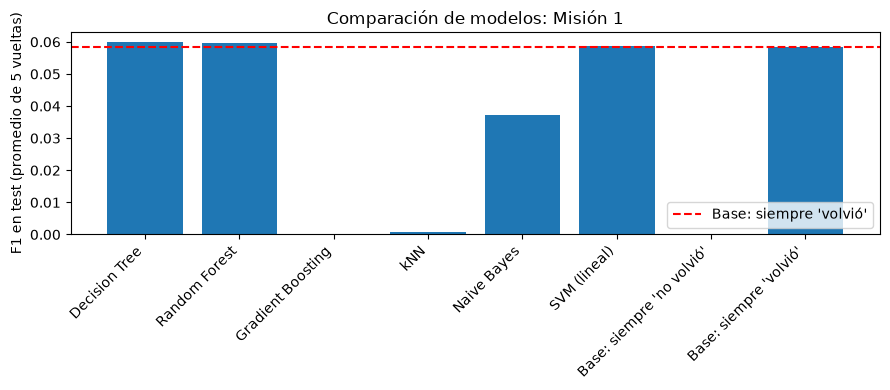

In [43]:
# guarda el valor del modelo de base para que se pueda ver sus diferencias.
base_volvio = tabla.loc["Base: siempre 'volvió'", "F1 test"]

plt.figure(figsize=(9, 4))
plt.bar(tabla.index, tabla["F1 test"])
plt.axhline(y=base_volvio, color="red", linestyle="--", label="Base: siempre 'volvió'")
plt.xticks(rotation=45, ha="right")
plt.ylabel("F1 en test (promedio de 5 vueltas)")
plt.title("Comparación de modelos: Misión 1")
plt.legend()
# ajusta los márgenes para que no se corten los nombres
plt.tight_layout()
plt.show()

Los modelos no son mucho mejores que el modelo base que responde siempre "volvió" con F1 = 0,058. Los únicos que lo superan apenas, son el Decision Tree, con 0,060, el Random Forest tambien con 0,060 y la SVM lineal con 0,059. Naive Bayes con 0,037 queda por debajo de la base, y Gradient Boosting con 0,000 y kNN con 0,001 casi nunca predicen que el cliente vuelve.

### Evaluación final con el conjunto de prueba

In [44]:
X_m1 = primeros[["dias_entrega", "customer_state", "review_score"]]
y_m1 = primeros["volvio"]
X_train_m1, X_test_m1, y_train_m1, y_test_m1 = train_test_split(X_m1, y_m1, test_size=0.2, random_state=36, stratify=y_m1)

modelo_final_m1 = Pipeline([("prep", preprocesador), ("modelo", LinearSVC(class_weight="balanced", dual="auto", random_state=42))])
modelo_final_m1.fit(X_train_m1, y_train_m1)
pred_m1 = modelo_final_m1.predict(X_test_m1)

print("F1:", round(f1_score(y_test_m1, pred_m1), 3))
print("Precision:", round(precision_score(y_test_m1, pred_m1), 3))
print("Recall:", round(recall_score(y_test_m1, pred_m1), 3))
confusion_matrix(y_test_m1, pred_m1)

F1: 0.058
Precision: 0.03
Recall: 0.668


array([[ 6140, 11972],
       [  186,   374]])

El SVM lineal se entrenó con todo el conjunto de entrenamiento y se evaluó una única vez con el conjunto de prueba. Obtuvo un F1 de 0,058, una Precision de 0,03 y un Recall de 0,668, el mismo F1 que el modelo de base que siempre responde "volvió" (0,058). En la matriz de confusión, detectó 374 clientes que volvieron, no detectó 186 y marcó como "volvió" a 11.972 clientes que no volvieron.

## Conclusiones de la Misión 1

Se definió que un cliente "volvió" si hizo más de una compra entregada, en lugar de la ventana de 30 días del enunciado, porque un cliente puede volver a comprar a los dos o tres meses y no por eso se fue. Solo el 3 % de las personas compró más de una vez, por lo que las clases están muy desbalanceadas.

La diferencia entre los tres mejores modelos es mínima porque tienen una mejora prácticamente nula con respecto al modelo base que dice a todos "vuelve", que tiene un **F1 de 0,058**. La diferencia es de **0,001 a 0,002** a favor del **Decision Tree**, con **0,060**, el **Random Forest**, también con **0,060**, y la **SVM** lineal, con **0,059**. Sin embargo, **Naive Bayes** queda por debajo de la base con **0,037**, y **Gradient Boosting** con **0,000** y **kNN** con **0,001**. Estos últimos tres modelos no admiten `class_weight`, por ende compitieron en diferentes condiciones que los primeros 3 modelos, puede que eso explique los resultados tan distintos. Los resultados de las comparaciones sugieren que las columnas usadas no alcanzan para distinguir a quien vuelve. En el entrenamiento hay solo 4.251 combinaciones distintas de valores entre 74.686 filas.

**Precision y Recall:** el Decision Tree, el Random Forest y la SVM lineal tienen un Recall de prueba de entre 0,498 y 0,623, pero una Precision de prueba de 0,031 a 0,032, casi igual a la de la base "siempre volvió" que es 0,030. No logran un buen balance entre las dos: detectan a una parte de los clientes que vuelven, pero marcan a muchos que no vuelven.

No se puede decir que el **Decision Tree** sea muy bueno para estos resultados, en la validación cruzada marcó como que volverían a **40.840** clientes que en realidad no volvieron, del total de **74.686** del entrenamiento. Eso se puede traducir en que el modelo gastará demasiados recursos de la empresa para mantener a esos clientes, y ofrecerles descuentos a todos ellos sería muy costoso. Su Precision fue de 0,031.

**Underfitting:** el Gradient Boosting tiene un **F1 de 0,004** en entrenamiento y **0,000** en prueba; el kNN, **0,008 y 0,001**; y el Decision Tree sin balanceo, unos **0,002 y 0**. Tienen resultados malos en las dos partes, así que no aprenden ni con los datos que ven. En cambio, el **sobreajuste** no es el problema principal de esta misión, porque las brechas entre entrenamiento y prueba de todos los modelos son chicas, de **0,003 a 0,011**.

Una posible mejora sería sumar información de otras tablas, aunque no hay garantía de que ayude. Otras posibles soluciones aparte de sumar más pistas podrían ser cambiar los valores de `class_weight` o ajustar algunos otros hiperparámetros. En ningún caso hay garantía de que mejore.

Se eligió usar **SVM lineal** y no **SVM con kernels** por la diferencia de **velocidad** de ambos.

**Utilizaría el modelo SVM lineal**. Porque su F1 en test es 0,059, prácticamente igual al del Decision Tree y el Random Forest, que son ambos 0,060, y tiene **0,003 de brecha** entre train y test, la menor de todos los modelos, por lo que es el modelo cuyo resultado parece más confiable. Aun así, no supera de forma clara al modelo base, así que esta elección es provisional hasta contar con mejores pistas. La **evaluación final** con el conjunto de prueba lo confirma: el SVM lineal obtuvo un F1 de 0,058, **igual al del modelo de base** que dice a todos "vuelve".

## Bonus: Modelos que parecían prometedores pero me traicionaron

Empezamos con el primero, el Random Forest. Por todo lo que siempre escuché y vi en internet le tenía mucha fe, pero sus números no cuadraron con las expectativas que tenía. En la validación logró un F1 de 0,060, apenas 0,002 sobre el modelo de base, con una Precision de 0,032 y un Recall de 0,498. Incluso con `class_weight`, quedó pegado a la base.

El segundo fue el Gradient Boosting. Por lo de ir aprendiendo de a poco pensé que podía tener mejores valores, pero solo obtuvo un F1 de 0,004 en entrenamiento y 0,000 en prueba, con un Recall también de 0,000. Una posible explicación, es que no admite `class_weight` y por eso casi nunca predice que el cliente vuelve.

Por último, tenemos a la SVM lineal, el modelo que elegí para esta misión, en la evaluación final tuvo el mismo valor de F1 que la base, 0,058.

Lo que muestran estos tres casos es que la potencia de un modelo no compensa que las columnas usadas no alcancen para distinguir a quien vuelve.

## Misión 3: Predicción de entregas
### Tabla de productos por pedido

In [45]:
items = pd.read_csv("archive/olist_order_items_dataset.csv")
print("shape:",items.shape)
items.info()
print("order_id #:",items["order_id"].nunique())
items.head()

shape: (112650, 7)
<class 'pandas.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   order_id             112650 non-null  str    
 1   order_item_id        112650 non-null  int64  
 2   product_id           112650 non-null  str    
 3   seller_id            112650 non-null  str    
 4   shipping_limit_date  112650 non-null  str    
 5   price                112650 non-null  float64
 6   freight_value        112650 non-null  float64
dtypes: float64(2), int64(1), str(4)
memory usage: 6.0 MB
order_id #: 98666


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


La tabla de productos por pedido tiene 112.650 filas y 7 columnas, sin valores nulos. Cada fila es un producto dentro de un pedido, con su id del producto, vendedor, fecha límite de envío, precio y valor del flete. Hay 98.666 pedidos distintos, por lo que algunos pedidos tienen más de un producto.

In [46]:
primer_producto = items.sort_values("order_item_id").drop_duplicates(subset="order_id")[["order_id", "product_id", "seller_id", "freight_value", "shipping_limit_date"]]
primer_producto.shape

(98666, 5)

En los pedidos con más de un producto se conservó solo el primero, para tener una fila por pedido, quedaron 98.666 filas. De esta tabla se mantienen el producto, el vendedor, el valor del flete y la fecha límite de envío. El precio se descarta porque no se espera que tenga relación con el tiempo de entrega.

### Tabla de productos

In [47]:
products = pd.read_csv("archive/olist_products_dataset.csv")
print(products.shape)
products.info()
print(products.isna().sum())
products.head()

(32951, 9)
<class 'pandas.DataFrame'>
RangeIndex: 32951 entries, 0 to 32950
Data columns (total 9 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   product_id                  32951 non-null  str    
 1   product_category_name       32341 non-null  str    
 2   product_name_lenght         32341 non-null  float64
 3   product_description_lenght  32341 non-null  float64
 4   product_photos_qty          32341 non-null  float64
 5   product_weight_g            32949 non-null  float64
 6   product_length_cm           32949 non-null  float64
 7   product_height_cm           32949 non-null  float64
 8   product_width_cm            32949 non-null  float64
dtypes: float64(7), str(2)
memory usage: 2.3 MB
product_id                      0
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_lengt

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0


La tabla de productos tiene 32.951 filas y 9 columnas. Hay 610 valores nulos en la categoría, el largo del nombre, el largo de la descripción y la cantidad de fotos, y 2 nulos en el peso y en cada una de las tres medidas del producto.

In [48]:
productos_utiles = products[["product_id", "product_category_name", "product_weight_g", "product_length_cm", "product_height_cm", "product_width_cm"]]
productos_utiles.shape

(32951, 6)

Se armó una tabla con los productos y solo las columnas elegidas, la categoría, el peso y las tres medidas del producto, largo, alto y ancho, además de `product_id`, que se usa solo para unir las tablas, la nueva tabla tiene 32.951 filas y 6 columnas. Se descartaron el largo del nombre, el largo de la descripción y la cantidad de fotos, porque no se espera que tengan relación con el tiempo de entrega. Los 610 nulos de la categoría se tratarán después de unir las tablas.

### Tabla de vendedores

In [49]:
sellers = pd.read_csv("archive/olist_sellers_dataset.csv")
print(sellers.shape)
sellers.info()
sellers.head()

(3095, 4)
<class 'pandas.DataFrame'>
RangeIndex: 3095 entries, 0 to 3094
Data columns (total 4 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   seller_id               3095 non-null   str  
 1   seller_zip_code_prefix  3095 non-null   int64
 2   seller_city             3095 non-null   str  
 3   seller_state            3095 non-null   str  
dtypes: int64(1), str(3)
memory usage: 96.8 KB


,seller_id,seller_zip_code_prefix,seller_city,seller_state
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,SP
2,ce3ad9de960102d0677a81f5d0bb7b2d,20031,rio de janeiro,RJ
3,c0f3eea2e14555b6faeea3dd58c1b1c3,4195,sao paulo,SP
4,51a04a8a6bdcb23deccc82b0b80742cf,12914,braganca paulista,SP


In [50]:
print("Seller nunique:",sellers["seller_id"].nunique())
print("Seller state nunique:",sellers["seller_state"].nunique())

Seller nunique: 3095
Seller state nunique: 23


La tabla de vendedores tiene 3.095 filas y 4 columnas, sin valores nulos. Cada vendedor aparece una sola vez y se ubica en uno de 23 estados, menos que los 27 de los clientes.

### Unión de tablas

In [51]:
m3 = entregados[entregados["dias_entrega"].notna()][["order_id", "order_purchase_timestamp", "customer_state", "dias_entrega"]]
print(m3.shape)

m3 = pd.merge(m3, primer_producto, on="order_id", how="left")
m3 = pd.merge(m3, productos_utiles, on="product_id", how="left")
m3 = pd.merge(m3, sellers[["seller_id", "seller_state"]], on="seller_id", how="left")
print(m3.shape)
print(m3.isna().sum())

(96470, 4)
(96470, 14)
order_id                       0
order_purchase_timestamp       0
customer_state                 0
dias_entrega                   0
product_id                     0
seller_id                      0
freight_value                  0
shipping_limit_date            0
product_category_name       1359
product_weight_g              16
product_length_cm             16
product_height_cm             16
product_width_cm              16
seller_state                   0
dtype: int64


Se unieron las tablas de pedidos, productos por pedido, productos y vendedores. La tabla resultante tiene 96.470 filas y 14 columnas, las uniones no agregaron ni perdieron pedidos. Quedan 1.359 valores nulos en la categoría del producto y 16 en el peso y en cada una de las tres medidas.

In [52]:
m3["shipping_limit_date"] = pd.to_datetime(m3["shipping_limit_date"])
m3["dias_limite_envio"] = (m3["shipping_limit_date"] - m3["order_purchase_timestamp"]).dt.days
print(m3["dias_limite_envio"].describe())
m3["product_category_name"].nunique()

count    96470.000000
mean         6.398538
std          4.629259
min          2.000000
25%          5.000000
50%          6.000000
75%          7.000000
max       1052.000000
Name: dias_limite_envio, dtype: float64


73

Se calculó el margen del vendedor como los días entre la compra y la fecha límite de envío. La mediana es de 6 días y el 75% de los pedidos tiene 7 días o menos, aunque el máximo es de 1.052 días, muy lejos del resto. Los productos pertenecen a 73 categorías distintas.

### Variables adicionales

In [53]:
m3 = pd.merge(m3, entregados[["order_id", "order_estimated_delivery_date"]], on="order_id", how="left")
m3["order_estimated_delivery_date"] = pd.to_datetime(m3["order_estimated_delivery_date"])
m3["dias_plazo_prometido"] = (m3["order_estimated_delivery_date"] - m3["order_purchase_timestamp"]).dt.days
print(m3.shape)
print(m3["dias_plazo_prometido"].describe())

(96470, 17)
count    96470.000000
mean        23.372748
std          8.758421
min          2.000000
25%         18.000000
50%         23.000000
75%         28.000000
max        155.000000
Name: dias_plazo_prometido, dtype: float64


Se agregó el plazo prometido, calculado como los días entre la compra y la fecha estimada de entrega que informa la plataforma. Su mediana es de 23 días y la mitad de los pedidos tiene un plazo entre 18 y 28 días, bastante más largo que el tiempo real de entrega, que de mediana son 10 días.

In [54]:
m3["pedidos_vendedor"] = m3["seller_id"].map(primer_producto["seller_id"].value_counts())
m3["pedidos_vendedor"].describe()

count    96470.000000
mean       373.041961
std        486.583472
min          1.000000
25%         51.000000
50%        150.000000
75%        463.000000
max       1844.000000
Name: pedidos_vendedor, dtype: float64

Se agregó el volumen de pedidos de cada vendedor, es decir, cuántos pedidos tiene en la tabla el vendedor de cada pedido. No quedaron valores nulos. La mediana es de 150 pedidos y el promedio de 373, y el máximo llega a 1.844, hay vendedores con volúmenes muy altos que elevan el promedio. Hay pedidos de vendedores con un solo pedido en toda la tabla.

### Separación en entrenamiento y prueba

In [55]:
X = m3[["customer_state","seller_state","product_category_name","freight_value","product_weight_g","product_length_cm","product_height_cm","product_width_cm","dias_limite_envio","dias_plazo_prometido","pedidos_vendedor"]]
y = m3["dias_entrega"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train.shape, X_test.shape

((77176, 11), (19294, 11))

Los datos se separaron en 80% para entrenamiento, 77.176 pedidos y 20% para prueba, 19.294, con 11 columnas como variables predictoras. Tres categóricas, estado del cliente, estado del vendedor y categoría del producto. Ocho numéricas, flete, peso, tres dimensiones, días hasta el límite de envío, plazo prometido y pedidos del vendedor.

### Preprocesamiento

In [56]:
numericas_m3 = ["freight_value","product_weight_g","product_length_cm","product_height_cm","product_width_cm","dias_limite_envio","dias_plazo_prometido","pedidos_vendedor"]
categoricas_m3 = ["customer_state", "seller_state", "product_category_name"]

# Números: solo se rellenan los nulos con la mediana
num_m3 = Pipeline([("imputer", SimpleImputer(strategy="median"))])

# Texto: strategy="constant" rellena nulos con "sin_categoria" y después One-Hot
cat_m3 = Pipeline([("imputer", SimpleImputer(strategy="constant", fill_value="sin_categoria")),
                   ("onehot", OneHotEncoder(handle_unknown="ignore"))])

prep_m3 = ColumnTransformer([("num", num_m3, numericas_m3), ("cat", cat_m3, categoricas_m3)])

X_train_prep = prep_m3.fit_transform(X_train)
X_train_prep.shape

(77176, 131)

El preprocesamiento deja listas las 11 variables de entrada. Las 8 numéricas pasan por un imputer de mediana, y las 3 categóricas por un imputer que rellena los nulos con "sin_categoria" y después por One-Hot Encoding. Tras la transformación, el modelo recibe 131 columnas.

### Métricas de evaluación

Para comparar los modelos se usan tres métricas: MAE, RMSE y R². Como métrica principal para elegir el mejor modelo se usa el MAE, porque se interpreta directamente como el error promedio en días. El RMSE se muestra como complemento, porque penaliza más los errores grandes, hay pedidos que tardan más de 60 días, y el R² indica cuánto mejora cada modelo respecto a uno que siempre predice el promedio.

### Modelo de base

In [57]:
resultados_m3 = {}

def evaluar_reg(nombre, modelo):
    pipe = Pipeline([("prep", prep_m3), ("modelo", modelo)])
    res = cross_validate(pipe, X_train, y_train, cv=5,
                         scoring=["neg_mean_absolute_error", "neg_root_mean_squared_error", "r2"],
                         return_train_score=True)
    resultados_m3[nombre] = {
        "MAE train": -res["train_neg_mean_absolute_error"].mean(),
        "MAE test": -res["test_neg_mean_absolute_error"].mean(),
        "RMSE train": -res["train_neg_root_mean_squared_error"].mean(),
        "RMSE test": -res["test_neg_root_mean_squared_error"].mean(),
        "R2 train": res["train_r2"].mean(),
        "R2 test": res["test_r2"].mean(),
    }
    print(nombre)
    print(pd.Series(resultados_m3[nombre]).round(3))

evaluar_reg("Base: promedio", DummyRegressor(strategy="mean"))

Base: promedio
MAE train     6.419
MAE test      6.419
RMSE train    9.609
RMSE test     9.609
R2 train      0.000
R2 test      -0.000
dtype: float64


Como modelo de base se usó un regresor que siempre predice el promedio de los días de entrega del conjunto de entrenamiento. En la cross-validation obtiene un MAE de 6,419 días, un RMSE de 9,609 y un R² de 0, tanto en entrenamiento como en prueba, ya que no aprende nada de las columnas. Cualquier modelo que valga la pena debería mejorar estos valores.

### Comparación de modelos
#### Decision Tree

In [58]:
evaluar_reg("Decision Tree sin límite", DecisionTreeRegressor(random_state=42))

Decision Tree sin límite
MAE train      0.108
MAE test       6.917
RMSE train     0.905
RMSE test     11.654
R2 train       0.991
R2 test       -0.472
dtype: float64


El Decision Tree sin límite de profundidad obtiene en la cross-validation un MAE de 0,108 días en entrenamiento y de 6,917 en prueba, y un R² de 0,991 y de −0,472, respectivamente. La diferencia entre ambos indica sobreajuste, el árbol memoriza los datos de entrenamiento y en datos nuevos queda peor que el modelo de base, MAE de 6,419 y R² de 0.

In [59]:
evaluar_reg("Decision Tree (profundidad 5)", DecisionTreeRegressor(max_depth=5, random_state=42))
evaluar_reg("Decision Tree (profundidad 10)", DecisionTreeRegressor(max_depth=10, random_state=42))
# min_samples_leaf exige que cada hoja tenga como mínimo de pedidos de entrenamiento.
evaluar_reg("Decision Tree (mín. 50 por hoja)", DecisionTreeRegressor(min_samples_leaf=50, random_state=42))

Decision Tree (profundidad 5)
MAE train     5.266
MAE test      5.280
RMSE train    8.485
RMSE test     8.540
R2 train      0.220
R2 test       0.210
dtype: float64
Decision Tree (profundidad 10)
MAE train     4.921
MAE test      5.223
RMSE train    7.898
RMSE test     8.740
R2 train      0.324
R2 test       0.172
dtype: float64
Decision Tree (mín. 50 por hoja)
MAE train     4.894
MAE test      5.216
RMSE train    7.990
RMSE test     8.458
R2 train      0.309
R2 test       0.225
dtype: float64


Se probaron tres Decision Trees con límites. Los tres mejoran al modelo de base, MAE de 6,419 y RMSE de 9,609. El árbol de profundidad 5 casi no muestra brecha entre entrenamiento y prueba, MAE de 5,266 y 5,280. El de profundidad 10 sí la tiene, 4,921 y 5,223, y su RMSE y R² en prueba empeoran respecto al de profundidad 5. El de mínimo 50 pedidos por hoja obtiene los mejores valores en prueba, MAE de 5,216, RMSE de 8,458 y R² de 0,225. Aun así, el R² es bajo, los árboles explican una parte pequeña de las variaciones en los días de entrega.

#### Random Forest

In [60]:
# n_jobs=-1 le dice a scikit-learn que use todos los núcleos de la computadora al mismo tiempo
evaluar_reg("Random Forest", RandomForestRegressor(n_estimators=100, min_samples_leaf=50, random_state=42, n_jobs=-1))

Random Forest
MAE train     4.813
MAE test      5.019
RMSE train    7.933
RMSE test     8.234
R2 train      0.318
R2 test       0.266
dtype: float64


El Random Forest, de 100 árboles, mínimo 50 pedidos por hoja, obtiene en la cross-validation un MAE de 4,813 días en entrenamiento y de 5,019 en prueba, un RMSE de 7,933 y 8,234, y un R² de 0,318 y 0,266. Mejora al mejor Decision Tree en las tres métricas de prueba, MAE de 5,216, RMSE de 8,458 y R² de 0,225, con una brecha pequeña entre entrenamiento y prueba. La mejora es modesta, el R² indica que el modelo explica una parte pequeña de las variaciones en los días de entrega.

#### Gradient Boosting

In [61]:
evaluar_reg("Gradient Boosting", GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, max_depth=3, min_samples_leaf=50, random_state=42))

Gradient Boosting
MAE train     5.055
MAE test      5.083
RMSE train    8.245
RMSE test     8.301
R2 train      0.264
R2 test       0.254
dtype: float64


El Gradient Boosting, 100 árboles, `learning_rate` de 0,1, profundidad 3 y mínimo 50 pedidos por hoja, obtiene en la cross-validation un MAE de 5,055 días en entrenamiento y de 5,083 en prueba, un RMSE de 8,245 y 8,301, y un R² de 0,264 y 0,254. Mejora al Decision Tree, pero queda levemente por detrás del Random Forest en las tres métricas de prueba, con una brecha muy pequeña entre entrenamiento y prueba.

### Tabla comparativa de modelos

In [62]:
nombres = ["Base: promedio", "Decision Tree (mín. 50 por hoja)", "Random Forest", "Gradient Boosting"]

tabla_m3 = pd.DataFrame(resultados_m3).T.loc[nombres]
tabla_m3["Brecha MAE"] = tabla_m3["MAE test"] - tabla_m3["MAE train"]
tabla_m3.round(3)

,MAE train,MAE test,RMSE train,RMSE test,R2 train,R2 test,Brecha MAE
Base: promedio,6.419,6.419,9.609,9.609,0.000,-0.000,0.000
Decision Tree (mín. 50 por hoja),4.894,5.216,7.990,8.458,0.309,0.225,0.322
Random Forest,4.813,5.019,7.933,8.234,0.318,0.266,0.205
Gradient Boosting,5.055,5.083,8.245,8.301,0.264,0.254,0.027


La tabla compara el modelo de base con los tres modelos. Los tres mejoran a la base en MAE, RMSE y R² de prueba. El Random Forest obtiene los mejores valores de prueba, MAE de 5,019 días, RMSE de 8,234 y R² de 0,266; seguido del Gradient Boosting, con 5,083, 8,301 y 0,254; y del Decision Tree con 5,216, 8,458 y 0,225. El Gradient Boosting es el que menos sobreajuste tiene, brecha de MAE de 0,027, el Random Forest queda en el medio, con 0,205, y el Decision Tree es el que más con 0,322.

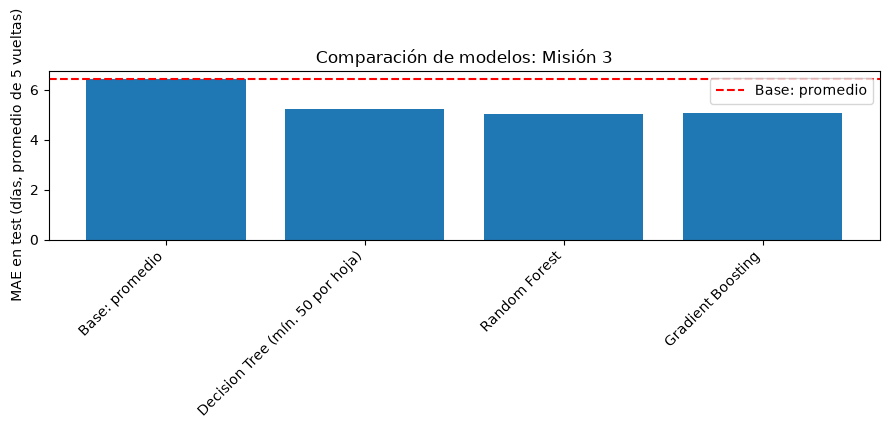

In [63]:
base_mae = tabla_m3.loc["Base: promedio", "MAE test"]

plt.figure(figsize=(9, 4))
plt.bar(tabla_m3.index, tabla_m3["MAE test"])
plt.axhline(y=base_mae, color="red", linestyle="--", label="Base: promedio")
plt.xticks(rotation=45, ha="right")
plt.ylabel("MAE en test (días, promedio de 5 vueltas)")
plt.title("Comparación de modelos: Misión 3")
plt.legend()
plt.tight_layout()
plt.show()

En el gráfico se puede ver que los tres modelos elegidos: Decision Tree, Random Forest y Gradient Boosting, superan al modelo base que siempre elige el promedio, teniendo errores menores que los del modelo base que consiguió un MAE de 6,419 en el test. Las diferencias entre los tres modelos elegidos son apenas visibles a simple vista porque tienen valores muy similares entre los tres: 5,216, 5,019 y 5,083. Recordemos que en estas comparaciones menos es mejor.

### Evaluación final con el conjunto de prueba

Evaluamos el Random Forest, que fue el elegido

In [64]:
modelo_final_m3 = Pipeline([("prep", prep_m3), ("modelo", RandomForestRegressor(n_estimators=100, min_samples_leaf=50, random_state=42, n_jobs=-1))])
modelo_final_m3.fit(X_train, y_train)
pred_m3 = modelo_final_m3.predict(X_test)

print("MAE:", round(mean_absolute_error(y_test, pred_m3), 3))
print("RMSE:", round(root_mean_squared_error(y_test, pred_m3), 3))
print("R2:", round(r2_score(y_test, pred_m3), 3))

MAE: 4.967
RMSE: 7.846
R2: 0.291


El Random Forest se entrenó con todo el conjunto de entrenamiento y se evaluó una única vez con el conjunto para prueba de 19.294 pedidos. Obtuvo un MAE de 4,967 días, un RMSE de 7,846 y un R² de 0,291, valores parecidos, y levemente mejores, que los de la cross-validation, 5,019, 8,234 y 0,266.

## Conclusiones de la Misión 3

La decisión de elegir el Random Forest se basa en los mejores valores de la tabla de resultados: MAE = **5,019**, RMSE = **8,234**, R² = **0,266**. Si bien su brecha no es la mejor **0,205**. Los valores del Gradient Boosting son peores, aunque por muy poco: MAE = **5,083**, RMSE = **8,301**, R²= **0,254** y con una brecha muy menor de **0,027**. Ya se había decidido que los valores a tener en cuenta para determinar el mejor eran, el **MAE** como principal, y el **RMSE** y el **R²**, por lo que se mantiene esa postura para sacar conclusiones. Como no medimos cuánto varían los resultados entre las vueltas, la ventaja del Random Forest sobre el Gradient Boosting es chica y no se puede asegurar que sea firme. 

En la **evaluación final** con el conjunto de prueba, el Random Forest obtuvo un **MAE de 4,967** días, un **RMSE de 7,846** y un **R² de 0,291**, valores parecidos a los de la cross-validation, lo que respalda que no hay un sobreajuste importante.

**Overfitting y underfitting:** El **Decision Tree sin límite** es un claro caso de **overfitting**, en entrenamiento tuvo un **R² de 0,991** y un **MAE de 0,108**, y en prueba los resultados empeoraron a un **R² de −0,472** y un **MAE de 6,917**. En cambio, el **Decision Tree con profundidad 5** es un caso de **underfitting**, tiene en entrenamiento un **MAE de 5,266** y un **R² de 0,220**, y en prueba un **MAE de 5,280** y un **R² de 0,210**, valores parecidos y los dos malos. Algo similar pasa con los otros modelos, incluso el Random Forest con 100 árboles tiene un R² de solo **0,318** en entrenamiento y **0,266** en prueba. Esto sugiere, como hipótesis, que las variables usadas no alcanzan para explicar los días de entrega.

El R² de 0,291 indica que el Random Forest explica entre un tercio y un cuarto de la variación de los días de entrega, el resto no lo explican las variables que usamos.

Aun siendo el mejor, el Random Forest, en promedio, se equivoca unos 5 días, sin importar si es para más o para menos. Es mucho, teniendo en cuenta que la mediana real de entrega es de 10 días y que 5 días pueden pasar la llegada de una semana a la siguiente. Por ejemplo, si el modelo promete el jueves y se equivoca 5 días, el pedido llega el martes de la semana siguiente. Los tres modelos tienen un error de alrededor de 5 días, frente a 6,419 de la base.

**Posible estrategia:** Esta información la empresa la podría utilizar para agregar de 3 a 5 días a los plazos de entrega que se le pasa al cliente, de esa forma cuando el pedido llegue antes no se sentiría como algo malo.

**Historial logístico:** Se utilizó el **plazo prometido** y el margen hasta la fecha límite de envío, que son datos del pedido mismo, no de un historial. Una variable más fiel sería el tiempo promedio histórico de entrega de cada vendedor, pero se calcula con los días de entrega, que es justamente lo que se busca predecir, por lo que habría que armarla solo con los datos de entrenamiento para evitar fuga de datos. No se hizo, y queda como una mejora posible.

**Limitaciones:**
- Usamos solo el primer producto de cada pedido; probablemente usar más ayudaría a predecir mejor, pero no lo probamos.
- Los pedidos de cada vendedor se contaron con toda la tabla, antes del split. Este conteo no usa los días de entrega, por lo que el efecto debería ser leve, pero no lo medimos.
- Los parámetros de los modelos (profundidad, mínimo por hoja) los probamos a mano con pocos valores, sin una búsqueda sistemática.
- No medimos cuánto varían los resultados entre las vueltas.
- El R² es bajo, hay mucha variación en los días de entrega que las variables usadas no capturan.

**Mejora posible:** probar una búsqueda sistemática de parámetros y sumar más información de los pedidos, como todos sus productos o una variable de historial por vendedor.

## Misión 5: Análisis de sentimientos

### Exploración de las reseñas

In [65]:
print("Con comentarios:",reviews["review_comment_message"].notna().sum(),"total:", len(reviews))
reviews["review_score"].value_counts()

Con comentarios: 40977 total: 99224


review_score
5    57328
4    19142
1    11424
3     8179
2     3151
Name: count, dtype: int64

La tabla tiene 99.224 reseñas, de las cuales solo 40.977 tienen comentario. Por puntaje, predominan las reseñas de 5 estrellas con 57.328, seguidas por las de 4 con 19.142. Las de 1 estrella son 11.424, las de 3 son 8.179 y las de 2 son 3.151. Los puntajes están muy cargados hacia los valores altos.

### Texto de entrada del modelo

In [66]:
print("Con título:", reviews["review_comment_title"].notna().sum())
print("Con comentario:", reviews["review_comment_message"].notna().sum())
print("Con título o comentario:", len(reviews.dropna(subset=["review_comment_title", "review_comment_message"], how="all")))

Con título: 11568
Con comentario: 40977
Con título o comentario: 42706


Hay 11.568 reseñas con título, 40.977 con comentario y 42.706 con alguno de los dos. Se decidió usar ambos textos juntos para el modelo, y quedarse con las reseñas que tienen al menos uno.

In [67]:
resenas = reviews.dropna(subset=["review_comment_title", "review_comment_message"], how="all")
resenas["texto"] = resenas["review_comment_title"].fillna("") + " " + resenas["review_comment_message"].fillna("")
print(resenas.shape)
resenas[["review_score", "texto"]].head()

(42706, 8)


,review_score,texto
3,5,Recebi bem antes do prazo estipulado.
4,5,Parabéns lojas lannister adorei comprar pela ...
9,4,recomendo aparelho eficiente. no site a marca ...
12,4,"Mas um pouco ,travando...pelo valor ta Boa.\r\n"
15,5,"Super recomendo Vendedor confiável, produto ok..."


Se conservaron las reseñas que tienen título o comentario, son 42.706, y se juntaron ambos textos en una sola columna, `texto`, rellenando con texto vacío en el que faltaba. Los textos están en portugués y algunos incluyen saltos de línea.

### Variable objetivo

In [68]:
resenas["negativa"] = resenas["review_score"].map({1: 1, 2: 1, 3: 1, 4: 0, 5: 0})
resenas["negativa"].value_counts()

negativa
0    28068
1    14638
Name: count, dtype: int64

Se creó la columna `negativa`, con 1 para las reseñas de 1, 2 o 3 estrellas y 0 para las de 4 o 5. De las 42.706 reseñas con texto, 14.638 son negativas y 28.068 positivas, es decir, las negativas son minoría.

### División en entrenamiento y prueba

In [69]:
X_m5 = resenas["texto"]
y_m5 = resenas["negativa"]
X_train_m5, X_test_m5, y_train_m5, y_test_m5 = train_test_split(X_m5, y_m5, test_size=0.2, random_state=42, stratify=y_m5)
print(X_train_m5.shape, X_test_m5.shape)
print(y_train_m5.value_counts(normalize=True))
print(y_test_m5.value_counts(normalize=True))

(34164,) (8542,)
negativa
0    0.657242
1    0.342758
Name: proportion, dtype: float64
negativa
0    0.657223
1    0.342777
Name: proportion, dtype: float64


Se separaron los datos en 34.164 reseñas para entrenamiento y 8.542 para prueba, es el 20 %. Al usar `stratify`, la proporción de reseñas negativas es casi igual en las dos partes, de aproximadamente 34,3 %.

### Modelo de base

In [70]:
resultados_m5 = {}

def evaluar_txt(nombre, modelo):
    pipe = Pipeline([("tfidf", TfidfVectorizer()), ("modelo", modelo)])
    res = cross_validate(pipe, X_train_m5, y_train_m5, cv=5, scoring=["f1", "precision", "recall"], return_train_score=True)
    resultados_m5[nombre] = {
        "F1 train": res["train_f1"].mean(), "F1 test": res["test_f1"].mean(),
        "Precision train": res["train_precision"].mean(), "Precision test": res["test_precision"].mean(),
        "Recall train": res["train_recall"].mean(), "Recall test": res["test_recall"].mean(),
    }
    print(nombre)
    print(pd.Series(resultados_m5[nombre]).round(3))

evaluar_txt("Base: siempre positiva", DummyClassifier(strategy="most_frequent"))

Base: siempre positiva
F1 train           0.0
F1 test            0.0
Precision train    0.0
Precision test     0.0
Recall train       0.0
Recall test        0.0
dtype: float64


Como modelo de base se usó uno que siempre responde "positiva". Su F1, su Precision y su Recall son 0 tanto en entrenamiento como en prueba, porque nunca detecta una reseña negativa.

### Naive Bayes

In [71]:
evaluar_txt("Naive Bayes", MultinomialNB())

Naive Bayes
F1 train           0.860
F1 test            0.835
Precision train    0.873
Precision test     0.850
Recall train       0.848
Recall test        0.821
dtype: float64


El Naive Bayes, con sus valores por defecto, obtiene en la cross-validation un F1 de 0,860 en entrenamiento y de 0,835 en prueba, una Precision de 0,873 y 0,850, y un Recall de 0,848 y 0,821. Supera ampliamente al modelo de base, cuyo F1 fue 0, y la brecha entre entrenamiento y prueba es pequeña, por lo que no muestra un sobreajuste importante.

### SVM lineal

In [72]:
evaluar_txt("SVM lineal", LinearSVC(random_state=42))

SVM lineal
F1 train           0.926
F1 test            0.845
Precision train    0.941
Precision test     0.857
Recall train       0.911
Recall test        0.833
dtype: float64


El SVM lineal obtiene en la cross-validation un F1 de 0,926 en entrenamiento y de 0,845 en prueba, una Precision de 0,941 y 0,857, y un Recall de 0,911 y 0,833. Es levemente mejor que el Naive Bayes en prueba, pero su brecha entre entrenamiento y prueba es mayor, lo que indica algo más de sobreajuste.

### Comparación de modelos

In [73]:
tabla_m5 = pd.DataFrame(resultados_m5).T
tabla_m5["Brecha F1"] = tabla_m5["F1 train"] - tabla_m5["F1 test"]
tabla_m5.round(3)

,F1 train,F1 test,Precision train,Precision test,Recall train,Recall test,Brecha F1
Base: siempre positiva,0.000,0.000,0.000,0.000,0.000,0.000,0.000
Naive Bayes,0.860,0.835,0.873,0.850,0.848,0.821,0.025
SVM lineal,0.926,0.845,0.941,0.857,0.911,0.833,0.081


La tabla compara el modelo de base con los dos modelos. Los dos superan ampliamente a la base, que tiene un F1 de 0. El SVM lineal obtiene los mejores valores de prueba en las tres métricas: F1 de 0,845, Precision de 0,857 y Recall de 0,833, contra 0,835, 0,850 y 0,821 del Naive Bayes. En cambio, el Naive Bayes es el que menos sobreajusta, con una brecha de F1 de 0,025 contra 0,081 del SVM lineal.

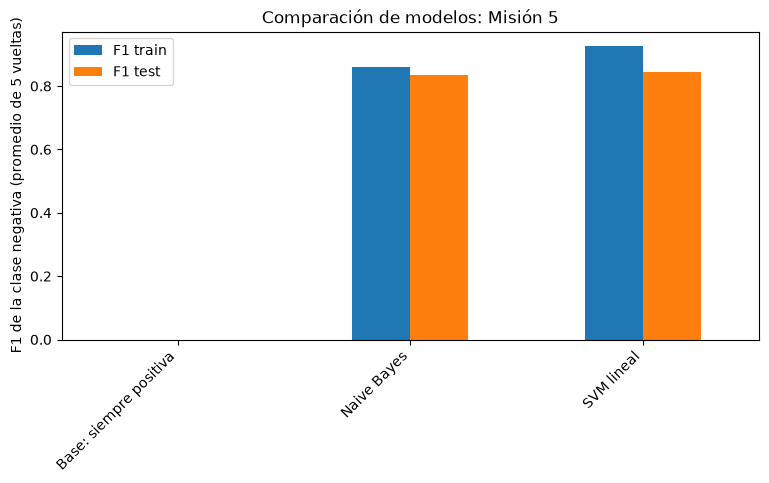

In [74]:
tabla_m5[["F1 train", "F1 test"]].plot(kind="bar", figsize=(9, 4))
plt.title("Comparación de modelos: Misión 5")
plt.ylabel("F1 de la clase negativa (promedio de 5 vueltas)")
plt.xticks(rotation=45, ha="right")
plt.show()

En el gráfico se ve que el modelo base no tiene barras, porque su F1 es 0 tanto en entrenamiento como en prueba. Los dos modelos quedan muy por encima de la base. El SVM lineal tiene el F1 de prueba más alto con 0,845 contra 0,835 del Naive Bayes, pero la diferencia entre ambos es pequeña. Se aprecia claramente que la diferencia entre entrenamiento y prueba del SVM lineal es mayor, por lo que presenta algo más de sobreajuste que el Naive Bayes. En este gráfico hay que recordar que un F1 más alto es mejor, y que cuanta más diferencia hay entre las dos barras de un modelo, más sobreajuste.

### Evaluación final con el conjunto de prueba

In [75]:
modelo_final = Pipeline([("tfidf", TfidfVectorizer()), ("modelo", MultinomialNB())])
modelo_final.fit(X_train_m5, y_train_m5)
pred_m5 = modelo_final.predict(X_test_m5)

print("F1:", round(f1_score(y_test_m5, pred_m5), 3))
print("Precision:", round(precision_score(y_test_m5, pred_m5), 3))
print("Recall:", round(recall_score(y_test_m5, pred_m5), 3))
confusion_matrix(y_test_m5, pred_m5)

F1: 0.842
Precision: 0.852
Recall: 0.833


array([[5189,  425],
       [ 489, 2439]])

El Naive Bayes se entrenó con todo el conjunto de entrenamiento y se evaluó una única vez con el conjunto de prueba (8.542 reseñas). Obtuvo un F1 de 0,842, una Precision de 0,852 y un Recall de 0,833, valores parecidos a los de la cross-validation. En la matriz de confusión, detectó 2.439 reseñas negativas, no detectó 489 y marcó como negativas 425 reseñas que eran positivas.

## Conclusiones de la Misión 5

Se elige el modelo **Naive Bayes** como el mejor de esta misión porque la diferencia entre su F1 de entrenamiento y el de prueba es de **0,025**, contra **0,081** del **SVM lineal**. Si bien este último tuvo un mayor F1 de prueba, **0,845** contra **0,835 del Naive Bayes**, la ventaja es pequeña, 0,010, y no medimos cuánto varían los resultados entre las vueltas, por lo que no se puede asegurar que sea firme. Se prioriza el modelo que sobreajusta menos.

El Naive Bayes tiene una **Precision de 0,850**, es decir, de las reseñas que predijo como negativas, el 85% realmente lo era, y un **Recall de 0,821**, es decir, de todas las reseñas negativas reales detecta el 82%. Un modelo así podría usarse para marcar automáticamente las reseñas negativas y priorizar su lectura, y a partir de ellas estudiar qué productos o vendedores concentran los problemas y si tienen que ver con los tiempos de entrega. Eso último no se analizó acá: es una hipótesis de uso, no un resultado. En la **evaluación final** con el conjunto de prueba, el Naive Bayes obtuvo un **F1 de 0,842**, una **Precision de 0,852** y un **Recall de 0,833**, valores parecidos a los de la cross-validation, lo que respalda que no hay un sobreajuste importante.

**Limitaciones:**
- Se tomaron como negativas las reseñas de 3 estrellas o menos. Es un criterio propio: las de 3 estrellas pueden ser mixtas, por ejemplo, conformes con el producto pero no con el envío, lo que puede meter ruido en la clase negativa.
- Solo se usaron las reseñas con título o comentario, 42.706 de 99.224, así que los resultados valen para ese tipo de reseñas y pueden no representar a quienes califican sin escribir.
- Se probaron solo dos modelos, con sus parámetros por defecto, `alpha` y `C`, y no se quitaron las palabras vacías del portugués.
- No se midió cuánto varían los resultados entre las vueltas de la cross-validation.

**Mejora sugerida:** probar otros valores de `alpha` y `C`, quitar las palabras vacías, o combinar varios modelos para mejorar la detección de malas experiencias.